# 14 Leslie 种群模型

> **模块**：动态模型 ｜ **数据**：无（内置示例） ｜ **依赖**：numpy、pandas、matplotlib

## 1. 问题背景

莱斯利（Leslie）模型是研究动物种群数量增长的重要模型，这一模型研究了种群中雌性动物的年龄分布和数量增长的规律。

在正常社会条件或自然条件下，生育率和死亡率是与群体的年龄构成息息相关的。我们需要对整个群体按年龄进行层次划分，构建与年龄相联系的人口模型。简单来说，Leslie模型就是一个预测人口按年龄组变化的离散模型。


## 2. 学习目标

- 了解 Leslie 模型的假设、建立和求解
- 掌握 Leslie 模型的 Python 实现


## 3. 环境与数据

- Jupyter 开发环境
- Python 3.10


## 4. 方法与实现

### 4.1 模型假设

下面以人口为例，其方法和思路适用于类似生物种群数量变化规律的研究。

1. 将时间离散化

由于男性、女性人口通常有一定的比例，假设其性别比为1:1，**Leslie模型只考虑女性人口的发展变化**。

假设女性最大年龄为S岁，将其等间隔划分成m个年龄组，即1,2,...,m组，不妨假设S为m的整数倍，每隔$S/m$年观察一次，现将时间也离散为时段$t_k,k=1,2,...$。

2. 记时段$t_k$第$i$年龄组的种群数量为$x_i(k)(i = 1,2,...,m)$，第$i$年龄组的生育率为$α_i$，第$i$年龄组的死亡率为$d_i$，$β_i = 1-d_i$称为第$i$年龄组的存活率，假设$α_i$,$d_i$不随时间变化。
3. 不考虑生存空间等自然资源的制约，不考虑意外灾难等困难对人口变化的影响。
4. 生育率仅与年龄段有关，存活率也仅与年龄段有关。

### 4.2 模型建立和求解

基于上述假设，在已知$t_k$时段的各值后，在$t_{k+1}$时段，第一年龄组种群数量是时段$t_k$各年龄组生育数量之和，即：

$$
x_1(k+1) = \sum_{i=1}^{m}{α_ix_i(k)}

$$

$t_{k+1}$时段第$i+1$年龄组的种群数量是时段$t_k$第$i$个年龄组存活下来的数量，即：

$$
x_{i+1}(k+1) = β_ix_i(k), \quad i = 1,2,...,m-1

$$

记在$t_k$时段种群各年龄组的数量为：

$$
x(k) =
\begin{bmatrix}
x_1(k) \\
x_2(k) \\
. \\
. \\
. \\
x_m(k)
\end{bmatrix}

$$

那么$t_{k+1}$时段种群各年龄组的数量为：

$$
x(k+1) = Lx(k),k=0,1,...

$$

其中：

$$
L=
\begin{bmatrix}
α_1 & α_2 & ... & α_{m-1} & α_m \\
β_1 & 0 & ... & 0 & 0 \\
0 & β_2 & ... & 0 & 0 \\
. & . &   & . & .  \\
. & . &   & . & . \\
. & . &   & . & . \\
0 & 0 & ... & β_{m-1} & 0
\end{bmatrix}

$$

即：

$$
\begin{bmatrix}
x_1(k+1) \\
x_2(k+1) \\
. \\
. \\
. \\
x_m(k+1)
\end{bmatrix}
=
\begin{bmatrix}
α_1 & α_2 & ... & α_{m-1} & α_m \\
β_1 & 0 & ... & 0 & 0 \\
0 & β_2 & ... & 0 & 0 \\
. & . &   & . & .  \\
. & . &   & . & . \\
. & . &   & . & . \\
0 & 0 & ... & β_{m-1} & 0
\end{bmatrix}
\begin{bmatrix}
x_1(k) \\
x_2(k) \\
. \\
. \\
. \\
x_m(k)
\end{bmatrix}

$$

给定在0时段，各年龄组的初始数量$x(0)$，就可以预测任意时段k各年龄组的数量：

$$
x(k) = L^kx(0),k = 0,1,2,...

$$

### 4.3 Python 实现

**例1**. 养殖场养殖一类动物最多三年（满三年的将送往市场卖掉），按一岁、二岁和三岁将其分为三个年龄组。一龄组是幼龄组，二龄组和三龄组是有繁殖后代能力的成年组，二龄组平均一年繁殖4个后代，三龄组平均一年繁殖3个后代。一龄组和二龄组动物能养殖成为下一年龄组动物的成活率分别为0.5和0.25。假设刚开始养殖时有三个年龄组的动物各1000头。

- （1）求五年内各年龄组动物数量
- （2）分析种群的增长趋势
- （3）如果每年平均向市场供应动物数$C = \begin{bmatrix}s \\ s \\ s \end{bmatrix}$，考虑每年都必须保持有每一年龄组的动物前提下，$s$应取多少为好。

#### 4.3.1 要求五年内各年龄组动物数量

设出生率向量$α = \begin{bmatrix}0 \\ 4.0 \\ 3.0 \end{bmatrix}$，记幼龄组、二龄组和三龄组动物第k年的数量分别为$x_1(k), x_2(k), x_3(k)$，$x(k) = \begin{bmatrix} x_1(k) \\ x_2(k) \\ x_3(k) \end{bmatrix}$。根据题目条件，建立如下差分方程模型：

$$
\begin{cases}
x_1(k+1) = 4x_2(k) + 3x_3(k) \\
x_2(k+1) = 0.5x_1(k) \\
x_3(k+1) = 0.25x_2(k)
\end{cases}

$$

写成矩阵形式：

$$
x(k+1) = L x(k), k=0,1,...

$$

$$
L=
\begin{bmatrix}
0 & 4 & 3 \\
0.5 & 0 & 0 \\
0 & 0.25 & 0
\end{bmatrix}

$$

利用初值条件$x(0) = \begin{bmatrix} 1000 \\ 1000 \\ 1000 \end{bmatrix}$，求五年内各年龄组动物数量。


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rc('font',family='SimHei')
plt.rc('axes',unicode_minus=False)
L = np.array([[0,4,3],[0.5,0,0],[0,0.25,0]])
X = 1000*np.ones((3,1))

# 查看三个年龄组五年的动物数量
# 构建一个三行五列全是0的矩阵
Xk=np.zeros((3,5))
for i in range(5):
    X=L.dot(X)  # 计算x1(k+1)，x2(k+1)，x3(k+1)
    Xk[:,i]=X.flatten() # 计算得到五年各年龄组动物数保存在Xk矩阵中
data = pd.DataFrame(data = Xk.T,index = [1,2,3,4,5],columns =['幼龄组','二龄组','三龄组'])
data.loc[0] = {'幼龄组':1000,'二龄组':1000,'三龄组':1000}  # 添加一行作为初始值
data = data.sort_index()
print('五年内各年龄组动物数量：')
data

五年内各年龄组动物数量：


,幼龄组,二龄组,三龄组
0,1000.00,1000.0,1000.000
1,7000.00,500.0,250.000
2,2750.00,3500.0,125.000
3,14375.00,1375.0,875.000
4,8125.00,7187.5,343.750
5,29781.25,4062.5,1796.875


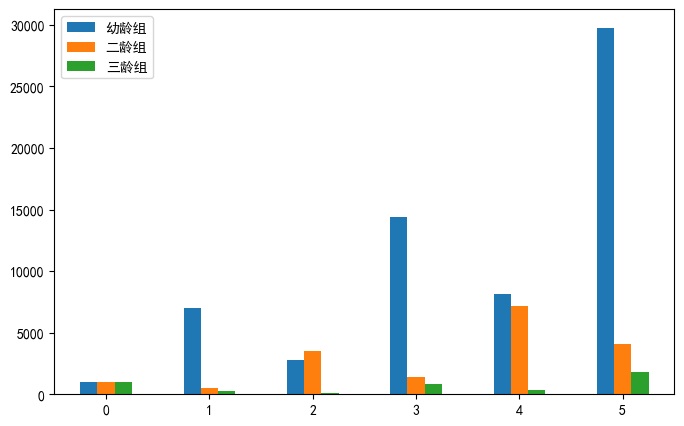

In [3]:
data.plot.bar(figsize = (8,5))
plt.xticks(rotation=0)
plt.show()

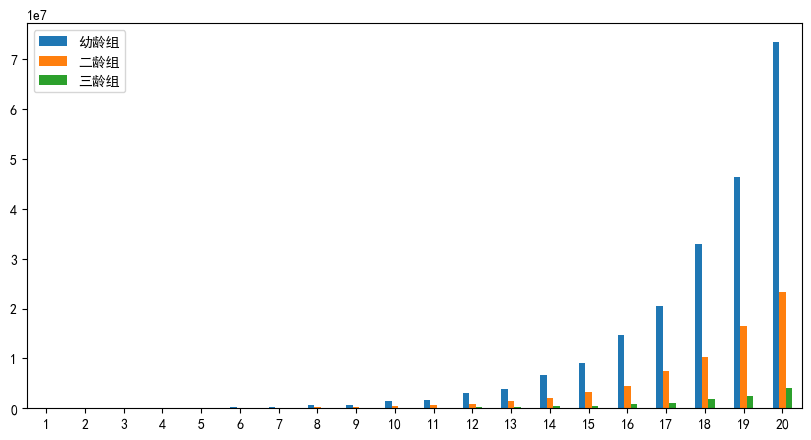

In [4]:
# 进一步查看20年各年龄组动物数
Xk=np.zeros((3,20))
for i in range(20):
    X=L.dot(X)
    Xk[:,i]=X.flatten()
data = pd.DataFrame(data = Xk.T,index = np.arange(1,21),columns =['幼龄组','二龄组','三龄组'])
data.plot.bar(figsize = (10,5))
plt.xticks(rotation=0)
plt.show()

#### 4.3.2 分析种群的增长趋势

为估计种群增长过程的动态趋势，首先研究一般的状态转移矩阵Leslie矩阵（L矩阵）的特征值和特征向量。

设$p(\lambda)$为Leslie矩阵的特征多项式，则：

$$
p(\lambda) = |\lambda I - L| = \lambda^m - \alpha_1 \lambda^{m-1} - \alpha_2 \beta_1 \lambda^{m-2} - \alpha_2 \beta_1 \beta_2 \lambda^{m-3} - \ldots - \alpha_2 \beta_1 \beta_2 \ldots \beta_{m-1}

$$

**定理1**. Leslie矩阵 $L$ 有唯一的正特征根 $\lambda_1$，它是单根，且相应的特征向量 $\mathbf{v}$ 的所有元素均为正数。

**定义1**. 设 $\lambda_1$ 是方阵 $L$ 的一个正特征根，若对 $L$ 的其他特征根 $\lambda$，恒有 $|\lambda| \leq \lambda_1$，则称 $\lambda_1$ 为 $L$ 的占优特征根。（若 $|\lambda| < \lambda_1$，称 $\lambda_1$ 为 $L$ 的严格占优特征根）

**定理2**. 如果Leslie矩阵 $L$ 的第一行中有两个相邻的元素 $\alpha_i$ 和 $\alpha_{i+1}$ 不为零，则 $L$ 的正特征根是严格占优的。

**利用Leslie模型分析人口增长，观察发现时间充分长后人口增长率和年龄分布结构均趋于一个稳定状态，这与矩阵 $L$ 的特征值和特征向量有关**。

假设矩阵 $L$ 可对角化，且由 $m$ 个特征根 $\lambda_1, \lambda_2, \ldots, \lambda_m$，以及对应于它们线性无关的特征向量 $\mathbf{v}_1, \mathbf{v}_2, \ldots, \mathbf{v}_m$，这些特征向量组成矩阵 $P = [\mathbf{v}_1, \mathbf{v}_2, \ldots, \mathbf{v}_m]$，则 $L$ 矩阵为：

$$
L = P
\begin{bmatrix}
\lambda_1 &   &   &   &   &   \\
& \lambda_2 &   &   &   &   \\
&   & \cdots &   &   &   \\
&   &   &  \cdots &  &   \\
&   &   &   &  \cdots &   \\
&   &   &   &     & \lambda_m
\end{bmatrix}
P^{-1}

$$

$$
L^k = P
\begin{bmatrix}
\lambda_1^k &   &   &   &   &   \\
& \lambda_2^k &   &   &   &   \\
&   & \cdots &   &   &   \\
&   &   &  \cdots &  &   \\
&   &   &   &  \cdots &   \\
&   &   &   &     & \lambda_m^k
\end{bmatrix}
P^{-1}

$$

对于任何一个给定的初始年龄分布向量 $x(0)$，$t_k$ 时段种群各年龄组的数量为：

$$
x(k) = L^k x(0) = P
\begin{bmatrix}
\lambda_1^k &   &   &   &   &   \\
& \lambda_2^k &   &   &   &   \\
&   & \cdots &   &   &   \\
&   &   &  \cdots &  &   \\
&   &   &   &  \cdots &   \\
&   &   &   &     & \lambda_m^k
\end{bmatrix}
P^{-1} x(0)

$$

由于 $\lambda_1$ 为严格占优的特征值，故 $|\frac{\lambda_i}{\lambda_1}| < 1, i = 2, 3, \ldots, m$，当 $k \to \infty$，也就是观察发现时间充分长时：

$$
\lim_{k \to \infty} \left( \frac{\lambda_i}{\lambda_1} \right)^k = 0, i = 2, 3, \ldots, m

$$

$$
\lim_{k \to \infty} \frac{x(k)}{\lambda_1^k} = P
\begin{bmatrix}
1 &   &   &   &   &   \\
& 0 &   &   &   &   \\
&   & \cdots &   &   &   \\
&   &   &  \cdots &  &   \\
&   &   &   &  \cdots &   \\
&   &   &   &     & 0
\end{bmatrix}
P^{-1} x(0)

$$

设向量 $[P^{-1} x(0)]_{m \times 1}$ 的一个元素为 $c$，则：

$$
\lim_{k \to \infty} \frac{x(k)}{\lambda_1^k} = P
\begin{bmatrix}
1 &   &   &   &   &   \\
& 0 &   &   &   &   \\
&   & \cdots &   &   &   \\
&   &   &  \cdots &  &   \\
&   &   &   &  \cdots &   \\
&   &   &   &     & 0
\end{bmatrix}
P^{-1} x(0)

$$
$$
= p
\begin{bmatrix}
c  \\
0 \\
\vdots \\
0 \\
\vdots \\
0
\end{bmatrix}

$$
$$
= [\mathbf{v}_1, \mathbf{v}_2, \ldots, \mathbf{v}_m]
\begin{bmatrix}
c  \\
0 \\
\vdots \\
0 \\
\vdots \\
0
\end{bmatrix}
= c \mathbf{v}_1

$$

其中 $c$ 为常数，仅与初始年龄分布有关，得到：

$$
\lim_{k \to \infty} \frac{x(k)}{\lambda_1^k} = c \mathbf{v}_1

$$

因此当 $k \to \infty$：

$$
\begin{cases}
x(k) \approx c \lambda_1^k \mathbf{v}_1 \\
x(k-1) \approx c \lambda_1^{k-1} \mathbf{v}_1
\end{cases}
\Rightarrow x(k) \approx \lambda_1 x(k-1)

$$

**这意味着对于充分长的时间，每个年龄分布向量就是它前一个年龄分布向量的 $\lambda_1$ 倍**。
1. 若 $\lambda_1 > 1$，则种群数量最终为增加。
2. 若 $\lambda_1 < 1$，则种群数量最终为减少。
3. 若 $\lambda_1 = 1$，则种群数量为稳定。

In [5]:
# 计算l矩阵的特征值和特征向量
v,vec = np.linalg.eig(L)
print("L矩阵特征值=",v,"\nL矩阵特征向量为：\n",vec)

L矩阵特征值= [ 1.5        -1.30901699 -0.19098301] 
L矩阵特征向量为：
 [[ 0.94736842 -0.93201073  0.225884  ]
 [ 0.31578947  0.35599642 -0.591372  ]
 [ 0.05263158 -0.06798927  0.774116  ]]


In [6]:
# 求c
# 先求矩阵P-1
P_inv = np.linalg.inv(vec)
# 定义初值条件x(0)
x0 = 1000*np.ones((3,1))
# 求P-1*x(0
P_inv_x0 = np.dot(P_inv,x0)
# 获取矩阵的第一个值为c
c = P_inv_x0[0]
print("常数c=",c[0])

常数c= 3000.0


$L$矩阵最大特征值$λ_1=1.5＞1$，因此当$k \to ∞$，该种群的数量趋近于无穷。

**如果每年平均向市场供应动物数 $C = \begin{bmatrix} s \\ s \\ s \end{bmatrix}$，考虑每年都必须保持有每一年龄组的动物前提下，$s$ 应取多少为好。**

此时：

$$
x(k+1) = Lx(k) - C, \quad k = 0, 1, 2, \ldots

$$

$$
\Rightarrow x(k) = L^k x(0) - (L^{k-1} + L^{k-2} + \ldots + L + I)C

$$

考虑到每年都必须保持有每一年龄组的动物，应该有$x(k)$的所有元素都要大于等于0。

In [7]:
# 考虑十年内每一年各年龄组动物数都大于0
# 定义s_value函数
def s_value(s,L,year=10):
    '''
    s:每年向市场供应动物数
    L:Leslie矩阵
    year:年数
    '''
    # 1.创建初始值x(0)
    X = np.ones(3)*1000
    # 2.创建year行3列全0矩阵
    Xk = np.zeros((year,3))
    # 3.根据年数循环
    for i in range(year):
        # S矩阵形状(3,)
        S = s*np.ones(3)
        # L矩阵形状(3,3),X矩阵形状(3,)
        X = np.dot(L,X)-S
        # L矩阵形状(year,3)
        Xk[i,:] = X.flatten()
    return Xk

In [8]:
# 对s的值进行for循环取值
for i in range(90,150):
    res = s_value(s=i,L=L,year=10)
    # 如果当前x(k)所有值都大于等于0，那么打印
    if (res>= 0).all():
        print("s={}时,x(k)的所有元素都大于等于0".format(i))

s=90时,x(k)的所有元素都大于等于0
s=91时,x(k)的所有元素都大于等于0
s=92时,x(k)的所有元素都大于等于0
s=93时,x(k)的所有元素都大于等于0
s=94时,x(k)的所有元素都大于等于0
s=95时,x(k)的所有元素都大于等于0
s=96时,x(k)的所有元素都大于等于0
s=97时,x(k)的所有元素都大于等于0
s=98时,x(k)的所有元素都大于等于0
s=99时,x(k)的所有元素都大于等于0
s=100时,x(k)的所有元素都大于等于0


所以，s值最大取100，能保证每一年龄组动物数量大于等于0。

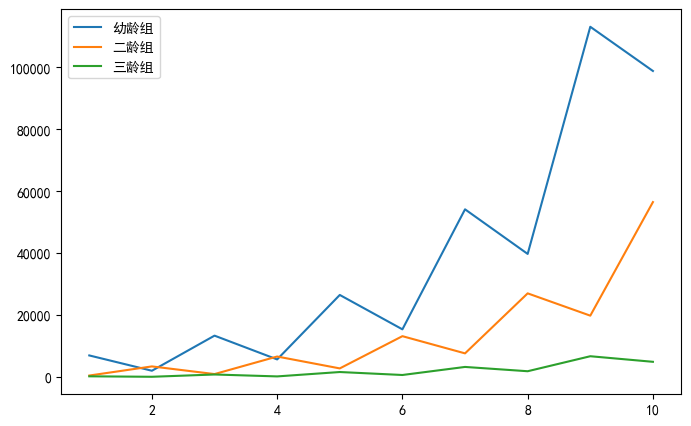

In [9]:
# 绘制十年间三个年龄组动物数的线形图
res = s_value(s=100,L=L,year=10)
# 设置图像画布大小
plt.figure(figsize=(8,5))
plt.plot(range(1,11),res)
# 设置图例
plt.legend(['幼龄组','二龄组','三龄组'])
plt.show()

## 5. 小结

本次实验介绍了Leslie种群模型的假设、建立和求解，实现了基于Python的Leslie模型种群数求解和分析。

通过本次实验需要掌握以下内容：
- 了解Leslie模型的假设、建立和求解
- 掌握Leslie模型的Python实现